## Import Packages

In [1]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly

from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score, recall_score, accuracy_score, f1_score, precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve,
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

print("All libraries imported successfully.")

All libraries imported successfully.


d:\Churn modelling\churn_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
import dagshub
import mlflow

DAGSHUB_USER_TOKEN = os.getenv("DAGSHUB_USER_TOKEN")

try:
    dagshub.init(repo_owner='Ankitkumar1141', repo_name='Churn-modelling', mlflow=True)
    mlflow.set_tracking_uri('https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow')
    mlflow.set_experiment('Experiment 8 - Stacking Classifier HP Tuning')
    print('MLflow tracking active on DagsHub.')
except Exception as e:
    print(f"[MLflow Notice] {e}")

Accessing as Ankitkumar1141

Initialized MLflow to track repo "Ankitkumar1141/Churn-modelling"

Repository Ankitkumar1141/Churn-modelling initialized!

2026/11/11 20:42:07 INFO mlflow.tracking.fluent: Experiment with name 'Experiment 8 - Stacking Classifier HP Tuning' does not exist. Creating a new experiment.


MLflow tracking active on DagsHub.


In [4]:
df = pd.read_csv("preprocessed.csv")
print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (10000, 37)


,customer_id,name,gender,age,salary,location_id,churned,account_id,tenure,balance,...,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female,geo_france,geo_germany,geo_spain,geo_uk,geo_usa
0,15634602,Hargrave,female,42,101348.88,2,1,A15634602SID,2,NaN,...,1,0,0.750000,0,1,1,0,0,0,0
1,15647311,Hill,female,41,112542.58,6,0,A15647311SID,1,83807.86,...,1,0,0.416667,0,1,0,0,0,0,1
2,15619304,Onio,female,42,113931.57,4,1,A15619304SID,8,159660.80,...,0,0,0.583333,0,1,0,0,0,1,0


## Exploratory Checks

In [5]:
df.dtypes

customer_id                  int64
name                        object
gender                      object
age                          int64
salary                     float64
location_id                  int64
churned                      int64
account_id                  object
tenure                       int64
balance                    float64
num_products                 int64
has_credit_card              int64
is_active                    int64
geography                   object
age_group                   object
salary_bracket              object
tenure_group                object
has_balance                  int64
churn_label                 object
has_credit_card_label       object
is_active_label             object
balance_to_salary          float64
balance_per_product        float64
age_when_joined              int64
products_per_tenure        float64
is_senior_risk               int64
is_extreme_product_risk      int64
is_single_product            int64
inactive_senior     

In [6]:
df.isna().sum().sort_values(ascending=False).head(5)

balance        3617
name              0
gender            0
age               0
customer_id       0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
print(df["churned"].value_counts())
churn_rate = df["churned"].mean()
print("\nChurn rate: {:.2%}".format(churn_rate))

churned
0    7963
1    2037
Name: count, dtype: int64

Churn rate: 20.37%


## Drop Unnecessary Columns

In [9]:
# Drop columns identified in prior notebooks as non-predictive or redundant
drop_columns = [
    "has_balance",
    "products_per_tenure",
    "has_credit_card",
    "geo_france", "geo_uk", "geo_usa", "geo_spain", "geo_germany",
    "tenure", "salary",
    "customer_id",
    "account_id", "name", "location_id",
    "age_when_joined", "age",
    "churn_label",
    "has_credit_card_label",
    "is_active_label",
]

df = df.drop(columns=drop_columns)
print("Shape after dropping columns:", df.shape)
df.head(3)

Shape after dropping columns: (10000, 18)


,gender,churned,balance,num_products,is_active,geography,age_group,salary_bracket,tenure_group,balance_to_salary,balance_per_product,is_senior_risk,is_extreme_product_risk,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female
0,female,1,NaN,1,1,france,36-45,high,new (0-2),0.000000,0.000000,0,0,1,0,0.750000,0,1
1,female,0,83807.86,1,1,usa,36-45,high,new (0-2),0.744670,83807.860000,0,0,1,0,0.416667,0,1
2,female,1,159660.80,3,0,uk,36-45,high,veteran (8-10),1.401362,53220.266667,0,1,0,0,0.583333,0,1


In [10]:
missing_cols = df.isna().any(axis=0).loc[lambda x: x].index.tolist()
print("Columns with missing values:", missing_cols)

Columns with missing values: ['balance']


In [11]:
pct_missing_rows = df.isna().any(axis=1).mean().round(4) * 100
n_missing = df.isna().any(axis=1).sum()
print(f"Rows with missing values: {pct_missing_rows:.2f}%  ({n_missing:,} rows)")

Rows with missing values: 36.17%  (3,617 rows)


## Train / Test Split

In [12]:
X = df.drop(columns="churned")
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Train size : {:,}  |  churn rate: {:.2%}".format(X_train.shape[0], y_train.mean()))
print("Test  size : {:,}  |  churn rate: {:.2%}".format(X_test.shape[0], y_test.mean()))

Train size : 8,000  |  churn rate: 20.38%
Test  size : 2,000  |  churn rate: 20.35%


In [13]:
print("Train shape:", X_train.shape)
print("Test  shape:", X_test.shape)
missing_in_train = X_train.isna().sum()
print("Missing in train (balance only):\n", missing_in_train[missing_in_train > 0])

Train shape: (8000, 17)
Test  shape: (2000, 17)
Missing in train (balance only):
 balance    2891
dtype: int64


## Column Type Identification

In [14]:
numeric_cols     = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
binary_cols      = [c for c in numeric_cols if X[c].nunique() == 2]
scale_cols       = [c for c in numeric_cols if c not in binary_cols]

print("Numeric (to scale) :", scale_cols)
print("Binary pass-thru   :", binary_cols)
print("Categorical OHE    :", categorical_cols)

Numeric (to scale) : ['balance', 'num_products', 'balance_to_salary', 'balance_per_product', 'engagement_score']
Binary pass-thru   : ['is_active', 'is_senior_risk', 'is_extreme_product_risk', 'is_single_product', 'inactive_senior', 'high_risk_inactive', 'is_female']
Categorical OHE    : ['gender', 'geography', 'age_group', 'salary_bracket', 'tenure_group']


## Preprocessing Pipeline

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale",          MinMaxScaler(), scale_cols),
        ("nominal_encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_cols),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

knn_imputer = KNNImputer(n_neighbors=10)

In [16]:
base_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  knn_imputer),
])

X_train_trans = base_pipeline.fit_transform(X_train)
X_test_trans  = base_pipeline.transform(X_test)

print("X_train transformed shape:", X_train_trans.shape)
print("X_test  transformed shape:", X_test_trans.shape)

X_train transformed shape: (8000, 28)
X_test  transformed shape: (2000, 28)


In [17]:
sampler = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = sampler.fit_resample(X_train_trans, y_train)

print("Before resampling — Train shape:", X_train_trans.shape)
print("After  resampling — Train shape:", X_train_resampled.shape)
print("Class distribution after resampling:")
print(y_train_resampled.value_counts())

Before resampling — Train shape: (8000, 28)
After  resampling — Train shape: (3260, 28)
Class distribution after resampling:
churned
0    1630
1    1630
Name: count, dtype: int64


## Base Estimators Setup

In [18]:
# Define tuned base models based on best parameters from Experiment 5 (XGB), 6 (RF), and 7 (LGBM)
xgb_base = XGBClassifier(
    n_estimators=271,
    max_depth=8,
    learning_rate=0.0253,
    subsample=0.8117,
    colsample_bytree=0.5525,
    min_child_weight=3,
    gamma=4.8089,
    reg_alpha=0.0068,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    eval_metric="logloss",
)

rf_base = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    max_samples=0.85,
    random_state=42,
    n_jobs=-1,
)

lgbm_base = LGBMClassifier(
    n_estimators=250,
    max_depth=6,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=20,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

print("Base estimators initialized.")

Base estimators initialized.


## Stacking Classifier Hyperparameter Tuning with Optuna

Optuna tunes:
1. `final_estimator` (meta-learner type: LogisticRegression vs RidgeClassifier vs LightGBM)
2. Meta-learner regularisation `C` or `learning_rate`
3. `passthrough` (whether original features are passed along with out-of-fold meta predictions)
4. Out-of-fold cross-validation fold count (`cv`)
5. Base estimator inclusion flags (XGB+RF vs XGB+LGBM vs All 3)

Logged under **Experiment 8 - Stacking Classifier HP Tuning**.

In [19]:
def objective(trial):
    with mlflow.start_run(nested=True):
        use_rf   = trial.suggest_categorical("use_rf", [True, False])
        use_lgbm = trial.suggest_categorical("use_lgbm", [True, False])
        
        # Ensure at least two base estimators
        estimators = [("xgb", xgb_base)]
        if use_rf:
            estimators.append(("rf", rf_base))
        if use_lgbm:
            estimators.append(("lgbm", lgbm_base))
        if len(estimators) < 2:
            estimators.append(("rf", rf_base))

        passthrough = trial.suggest_categorical("passthrough", [True, False])
        meta_type   = trial.suggest_categorical("meta_learner", ["lr", "lgbm"])
        
        if meta_type == "lr":
            C = trial.suggest_float("meta_C", 1e-3, 10.0, log=True)
            meta_learner = LogisticRegression(C=C, max_iter=500, random_state=42)
        else:
            lr_rate = trial.suggest_float("meta_lr", 0.01, 0.2, log=True)
            meta_learner = LGBMClassifier(n_estimators=50, learning_rate=lr_rate, max_depth=3, random_state=42, verbosity=-1)

        stacking_clf = StackingClassifier(
            estimators=estimators,
            final_estimator=meta_learner,
            passthrough=passthrough,
            cv=5,
            n_jobs=-1,
        )

        cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_scores = cross_validate(
            stacking_clf,
            X_train_resampled,
            y_train_resampled,
            cv=cv_strat,
            scoring={"roc_auc": "roc_auc", "recall": "recall", "f1": "f1"},
            n_jobs=1,
        )

        mean_auc    = cv_scores["test_roc_auc"].mean()
        mean_recall = cv_scores["test_recall"].mean()
        mean_f1     = cv_scores["test_f1"].mean()

        mlflow.log_params(trial.params)
        mlflow.log_metric("cv_mean_roc_auc", mean_auc)
        mlflow.log_metric("cv_mean_recall", mean_recall)
        mlflow.log_metric("cv_mean_f1", mean_f1)

        return mean_auc

In [20]:
study = optuna.create_study(direction="maximize", study_name="stacking_hp_tuning")

with mlflow.start_run(run_name="Stacking — Best Model") as parent:
    study.optimize(objective, n_trials=25, n_jobs=1, show_progress_bar=True)
    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_cv_roc_auc", study.best_value)

print("Best CV ROC-AUC :", round(study.best_value, 4))
print("Best Parameters:", study.best_params)

  0%|          | 0/25 [00:00<?, ?it/s]

🏃 View run resilient-midge-396 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7/runs/4b6afbdcb9f544518eda6b8b35f8917f
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7


Best trial: 0. Best value: 0.844686:   4%|▍         | 1/25 [01:19<31:39, 79.15s/it]

🏃 View run redolent-panda-563 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7/runs/6325361c26c042da8e988bd0940f70f5
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7


Best trial: 0. Best value: 0.844686:   8%|▊         | 2/25 [02:09<23:53, 62.31s/it]

🏃 View run bold-kit-507 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7/runs/87aba19f979b4e678449d47b55d4dfb8
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7


... (42 outputs left out)

Best trial: 15. Best value: 0.845659:  96%|█████████▌| 24/25 [19:28<00:48, 48.46s/it]

🏃 View run dashing-cow-621 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7/runs/7c4c0814ddf74b26b42ae62fcb9fa89d
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7


Best trial: 15. Best value: 0.845659: 100%|██████████| 25/25 [20:15<00:00, 48.63s/it]


🏃 View run Stacking — Best Model at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7/runs/228f17123d504e8e9ea7f25478971e4b
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7
Best CV ROC-AUC : 0.8457
Best Parameters: {'use_rf': False, 'use_lgbm': False, 'passthrough': False, 'meta_learner': 'lr', 'meta_C': 9.651361410333818}


## Train Best Model & Evaluate on Test Set

In [21]:
# Build champion stacking classifier using best trial params
best_p = study.best_params

est = [("xgb", xgb_base)]
if best_p.get("use_rf", True):
    est.append(("rf", rf_base))
if best_p.get("use_lgbm", True):
    est.append(("lgbm", lgbm_base))
if len(est) < 2:
    est.append(("rf", rf_base))

if best_p.get("meta_learner", "lr") == "lr":
    meta = LogisticRegression(C=best_p.get("meta_C", 1.0), max_iter=500, random_state=42)
else:
    meta = LGBMClassifier(n_estimators=50, learning_rate=best_p.get("meta_lr", 0.05), max_depth=3, random_state=42, verbosity=-1)

best_stacking = StackingClassifier(
    estimators=est,
    final_estimator=meta,
    passthrough=best_p.get("passthrough", False),
    cv=5,
    n_jobs=-1,
)

best_stacking.fit(X_train_resampled, y_train_resampled)
print("Best Stacking Classifier trained.")

Best Stacking Classifier trained.


In [22]:
y_pred_train = best_stacking.predict(X_train_trans)
y_pred_test  = best_stacking.predict(X_test_trans)
y_prob_train = best_stacking.predict_proba(X_train_trans)[:, 1]
y_prob_test  = best_stacking.predict_proba(X_test_trans)[:, 1]

print(f"Train accuracy : {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test  accuracy : {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Train recall   : {recall_score(y_train, y_pred_train):.4f}")
print(f"Test  recall   : {recall_score(y_test, y_pred_test):.4f}")
print(f"Train ROC-AUC  : {roc_auc_score(y_train, y_prob_train):.4f}")
print(f"Test  ROC-AUC  : {roc_auc_score(y_test, y_prob_test):.4f}")

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_test, target_names=["Stayed", "Churned"]))

Train accuracy : 0.7891
Test  accuracy : 0.7715
Train recall   : 0.8049
Test  recall   : 0.7518
Train ROC-AUC  : 0.8868
Test  ROC-AUC  : 0.8509

=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.84      1593
     Churned       0.46      0.75      0.57       407

    accuracy                           0.77      2000
   macro avg       0.69      0.76      0.71      2000
weighted avg       0.83      0.77      0.79      2000



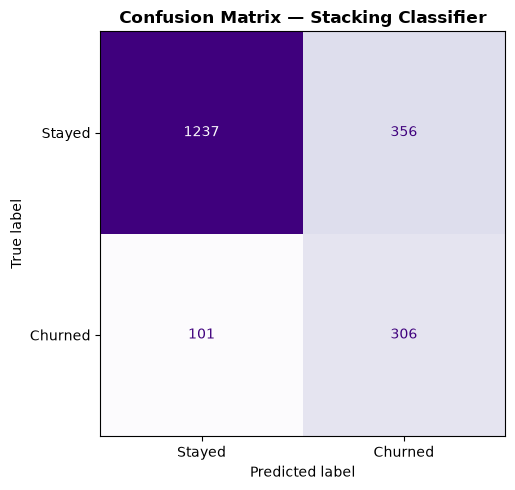

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stayed", "Churned"])
disp.plot(ax=ax, colorbar=False, cmap="Purples")
ax.set_title("Confusion Matrix — Stacking Classifier", fontweight="bold")
plt.tight_layout()
plt.show()

## Cross-Validation

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc"  : "roc_auc",
    "recall"   : "recall",
    "precision": "precision",
    "f1"       : "f1",
    "accuracy" : "accuracy",
}

In [25]:
cv_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  KNNImputer(n_neighbors=10)),
    ("sampler",      RandomUnderSampler(random_state=42)),
    ("classifier",   best_stacking),
])

cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1,
)

results_df = pd.DataFrame(cv_results)
print("=== CV Summary (5-Fold Stratified) ===")
print(f"Mean CV ROC-AUC  : {results_df['test_roc_auc'].mean():.4f} +/- {results_df['test_roc_auc'].std():.4f}")
print(f"Mean CV Recall   : {results_df['test_recall'].mean():.4f} +/- {results_df['test_recall'].std():.4f}")
print(f"Mean CV F1       : {results_df['test_f1'].mean():.4f} +/- {results_df['test_f1'].std():.4f}")
print(f"Mean CV Accuracy : {results_df['test_accuracy'].mean():.4f} +/- {results_df['test_accuracy'].std():.4f}")

=== CV Summary (5-Fold Stratified) ===
Mean CV ROC-AUC  : 0.8386 +/- 0.0133
Mean CV Recall   : 0.7301 +/- 0.0249
Mean CV F1       : 0.5540 +/- 0.0091
Mean CV Accuracy : 0.7605 +/- 0.0081


## Log Experiment to MLflow

In [26]:
try:
    with mlflow.start_run(run_name="Stacking Classifier — Final Evaluation"):
        mlflow.log_param("experiment_type", "Stacking Classifier HP Tuning")
        mlflow.log_param("imbalance_strategy", "RandomUnderSampler")
        mlflow.log_params(best_p)
        mlflow.log_metric("test_roc_auc", roc_auc_score(y_test, y_prob_test))
        mlflow.log_metric("test_recall", recall_score(y_test, y_pred_test))
        mlflow.log_metric("test_f1", f1_score(y_test, y_pred_test))
        mlflow.log_metric("test_accuracy", accuracy_score(y_test, y_pred_test))
        mlflow.log_metric("cv_mean_roc_auc", results_df['test_roc_auc'].mean())
        mlflow.log_metric("cv_mean_recall", results_df['test_recall'].mean())
        
        signature = mlflow.models.infer_signature(
            model_input=X_train_resampled.sample(20, random_state=42),
            model_output=best_stacking.predict_proba(X_train_resampled.sample(20, random_state=42))[:, 1],
        )
        mlflow.sklearn.log_model(best_stacking, artifact_path="stacking_model", signature=signature)
    print("Logged to MLflow successfully.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

2026/11/11 21:03:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Stacking Classifier — Final Evaluation at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7/runs/be6c5e10380a46d4a92d6c87403a5832
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/7
[MLflow Notice] The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['sklearn.utils._bunch.Bunch', 'xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier'].


## Final Summary

In [27]:
summary = pd.DataFrame({
    "Metric": ["Test ROC-AUC", "Test Recall", "Test Precision", "Test F1", "Test Accuracy", "CV ROC-AUC (mean)", "CV Recall (mean)"],
    "XGB Tuned": [0.8492, 0.7518, 0.4525, 0.5736, 0.7725, 0.8389, 0.7209],
    "Stacking (This Notebook)": [
        round(roc_auc_score(y_test, y_prob_test), 4),
        round(recall_score(y_test, y_pred_test), 4),
        round(precision_score(y_test, y_pred_test), 4),
        round(f1_score(y_test, y_pred_test), 4),
        round(accuracy_score(y_test, y_pred_test), 4),
        round(results_df["test_roc_auc"].mean(), 4),
        round(results_df["test_recall"].mean(), 4),
    ],
})
summary

,Metric,XGB Tuned,Stacking (This Notebook)
0,Test ROC-AUC,0.8492,0.8509
1,Test Recall,0.7518,0.7518
2,Test Precision,0.4525,0.4622
3,Test F1,0.5736,0.5725
4,Test Accuracy,0.7725,0.7715
5,CV ROC-AUC (mean),0.8389,0.8386
6,CV Recall (mean),0.7209,0.7301
